In [ ]:
import matplotlib.pyplot as plt
import numpy as np

!pip install neurokit2 py-ecg-detectors hrv-analysis
import neurokit2 as nk
from ecgdetectors import Detectors
import astropy.stats
from astropy.timeseries import LombScargle
astropy.stats.LombScargle = LombScargle

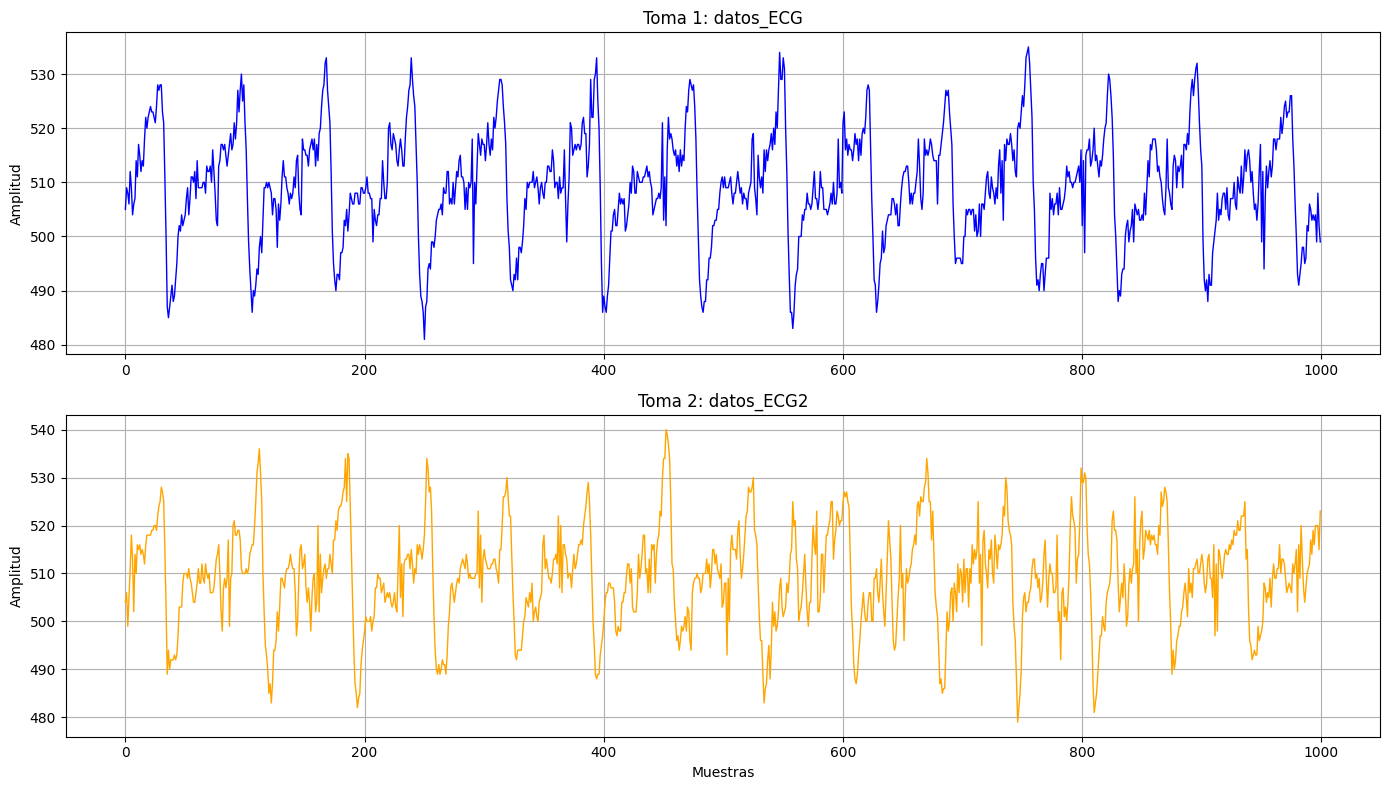

In [ ]:
from hrvanalysis import get_time_domain_features, remove_outliers, interpolate_nan_values

try:
    ecg1 = np.loadtxt("datos_ECG.txt")
except:
    ecg1 = np.loadtxt("datos_ECG")

try:
    ecg2 = np.loadtxt("datos_ECG2.txt")
except:
    ecg2 = np.loadtxt("datos_ECG2")


plt.figure(figsize=(14, 8))

plt.subplot(2, 1, 1)
plt.plot(ecg1, color="blue", linewidth=1)
plt.title("Toma 1: datos_ECG")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(ecg2, color="orange", linewidth=1)
plt.title("Toma 2: datos_ECG2")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

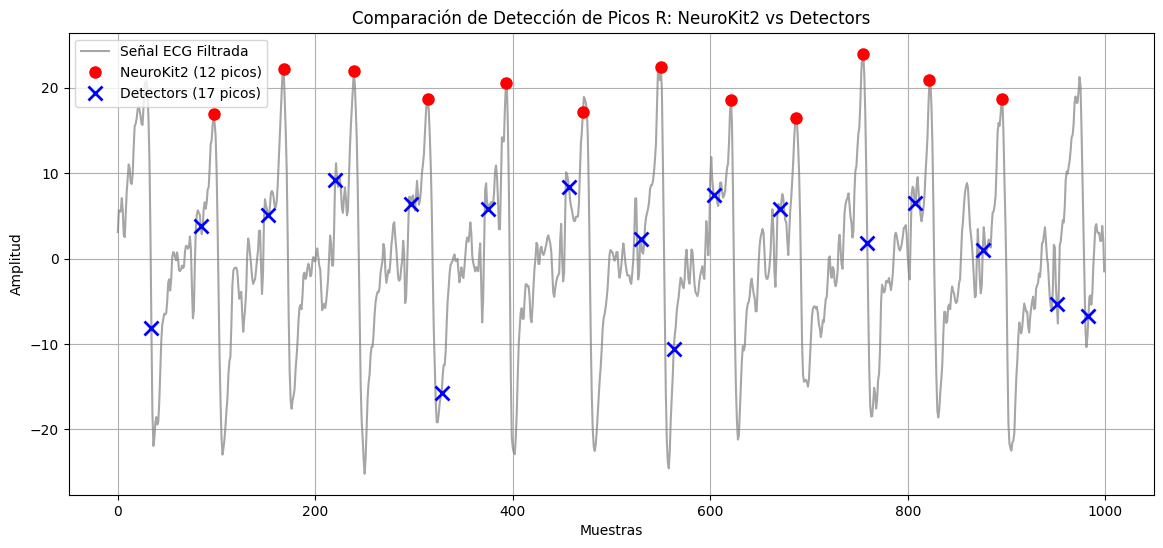

Intervalos RR (ms): [710 710 750 790 780 790 710 660 680 670 730]
0 outlier(s) have been deleted.

 CARACTERÍSTICAS DE HRV EN EL DOMINIO DEL TIEMPO 
mean_nni    : 725.45
sdnn        : 46.98
sdsd        : 40.45
nni_50      : 2.00
pnni_50     : 20.00
nni_20      : 5.00
pnni_20     : 50.00
rmssd       : 40.50
median_nni  : 710.00
range_nni   : 130.00
cvsd        : 0.06
cvnni       : 0.06
mean_hr     : 83.02
max_hr      : 90.91
min_hr      : 75.95
std_hr      : 5.10


In [ ]:
try:
    ecg_signal = np.loadtxt("datos_ECG.txt")
except:
    ecg_signal = np.loadtxt("datos_ECG")

sampling_rate = 100
ecg_cleaned = nk.ecg_clean(ecg_signal, sampling_rate=sampling_rate)

_, r_peaks_nk = nk.ecg_peaks(ecg_cleaned, sampling_rate=sampling_rate, correct_artifacts=True)
peaks_nk = r_peaks_nk["ECG_R_Peaks"]

detectors = Detectors(sampling_rate)
peaks_detectors = np.array(detectors.hamilton_detector(ecg_cleaned))

plt.figure(figsize=(14, 6))
plt.plot(ecg_cleaned, label="Señal ECG Filtrada", color="gray", alpha=0.7)
plt.plot(peaks_nk, ecg_cleaned[peaks_nk], "ro", markersize=8, label=f"NeuroKit2 ({len(peaks_nk)} picos)")
plt.plot(peaks_detectors, ecg_cleaned[peaks_detectors], "bx", markersize=10, mew=2, label=f"Detectors ({len(peaks_detectors)} picos)")
plt.title("Comparación de Detección de Picos R: NeuroKit2 vs Detectors")
plt.xlabel("Muestras"); plt.ylabel("Amplitud"); plt.legend(); plt.grid(True)
plt.show()

rr_intervals_ms = list(np.diff(peaks_nk) * (1000 / sampling_rate))
print("Intervalos RR (ms):", np.round(rr_intervals_ms).astype(int))

rr_limpio = remove_outliers(rr_intervals=rr_intervals_ms, low_rri=300, high_rri=2000)
rr_limpio = interpolate_nan_values(rr_intervals=rr_limpio, interpolation_method="linear")

time_domain_features = get_time_domain_features(rr_limpio)

print(" CARACTERÍSTICAS DE HRV EN EL DOMINIO DEL TIEMPO ")
for metrica, valor in time_domain_features.items():
    if valor is not None:
        print(f"{metrica:<12}: {valor:.2f}")